# TinyML -- Extremely Randomized Trees

**Author:** Thommas Kevin Sales Flores  
**Institution:** Federal University of Rio Grande do Norte  
**Email:** thommas.flores@ufrn.br

---

This notebook demonstrates how to build, train, evaluate, and export
**Extremely Randomized Trees** ensembles to embedded hardware
(Arduino / ESP32) using the TinyML framework.

Extra Trees extend Random Forests by randomising split thresholds
in addition to feature subsets, producing faster training and competitive
generalisation with lower variance.

### Supported building blocks

| Component | Options |
|---|---|
| **Criterion** | `gini`, `entropy` (classification); `mse`, `mae` (regression) |
| **max_features** | `sqrt`, `log2`, integer, `None` (all) |
| **Pruning** | cost-complexity (`vi.cost_complexity_prune`), min-gain (`vi.min_impurity_prune`) |
| **Uncertainty** | ensemble variance (`vi.prediction_variance`) |
| **Explainability** | MDI importance, permutation importance, partial dependence |
| **Export** | JSON -> Arduino C++ (AVR PROGMEM or ESP32) |


In [1]:
#!pip install numpy matplotlib scikit-learn

In [2]:
import sys, os
sys.path.append('41_ERT')

import numpy as np
from sklearn.datasets import load_iris, load_breast_cancer, load_wine, make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from model  import ExtraTreesModel
from layers import CRITERION_NAMES, CRITERION_NAMES
from losses import LOSS_NAMES, compute_loss
from utils  import (
    export_to_json,
    train_model,
    plot_training_history,
    plot_tree,
    plot_feature_importance,
    plot_decision_boundary,
    plot_regression_fit,
    plot_partial_dependence,
    plot_prediction_variance,
    evaluate_metrics,
)
from cpp_generator import generate_ino

print('Criteria    :', CRITERION_NAMES)
print('Metrics     :', LOSS_NAMES)

os.makedirs('json_model',   exist_ok=True)
os.makedirs('arduino_code', exist_ok=True)

Criteria    : ['gini', 'entropy', 'mse', 'mae']
Metrics     : ['accuracy', 'log_loss', 'precision', 'recall', 'f1', 'mse', 'mae', 'rmse', 'r2', 'mape']


---
## Example 1 -- Iris: Multi-Class Classification

We train an Extra Trees ensemble on the 4-feature Iris dataset and visualise
the decision boundary, feature importance (MDI vs permutation), and the
structure of a single tree from the ensemble.

=== Example 1 -- Iris Multi-Class Classification ===
  Trees   20/100  |  ACCURACY = 0.921053
  Trees   40/100  |  ACCURACY = 0.947368
  Trees   60/100  |  ACCURACY = 0.921053
  Trees   80/100  |  ACCURACY = 0.947368
  Trees  100/100  |  ACCURACY = 0.921053


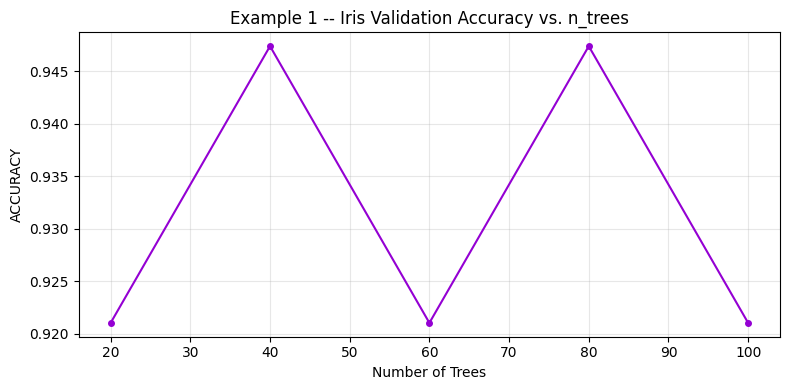

In [3]:
print('=== Example 1 -- Iris Multi-Class Classification ===')

iris = load_iris()
X_tr1, X_te1, y_tr1, y_te1 = train_test_split(
    iris.data.astype(np.float64), iris.target,
    test_size=0.25, random_state=42, stratify=iris.target,
)

et1 = ExtraTreesModel(
    n_estimators=100,
    task='classification',
    criterion='gini',
    max_depth=None,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
)
history1 = train_model(
    et1, X_tr1, y_tr1,
    X_val=X_te1, y_val=y_te1,
    metric='accuracy', log_every=20,
)
plot_training_history(history1, metric_name='Accuracy',
                      title='Example 1 -- Iris Validation Accuracy vs. n_trees')

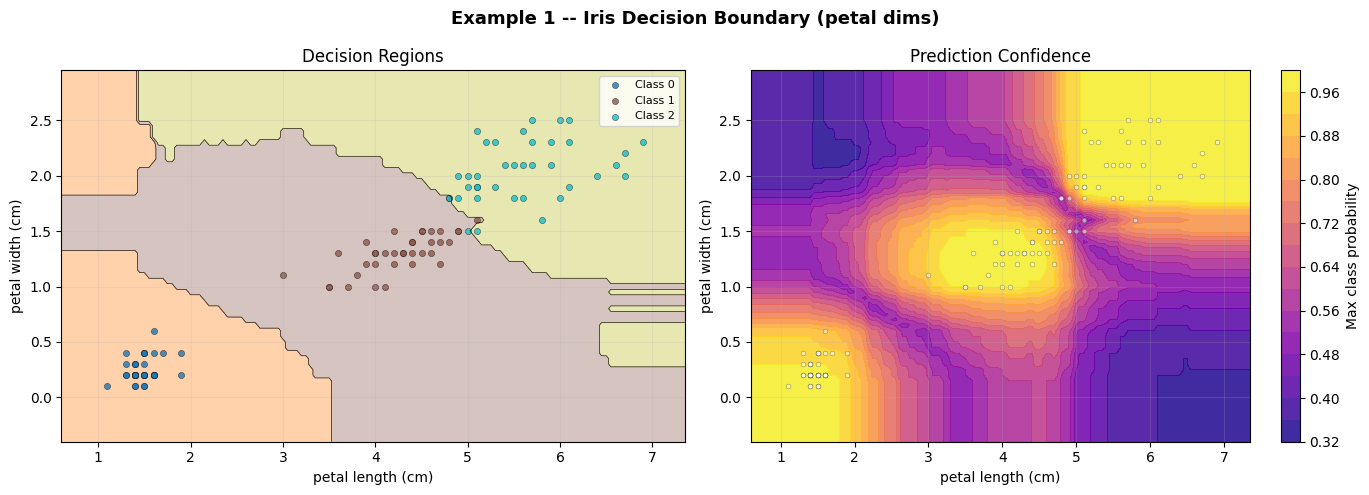

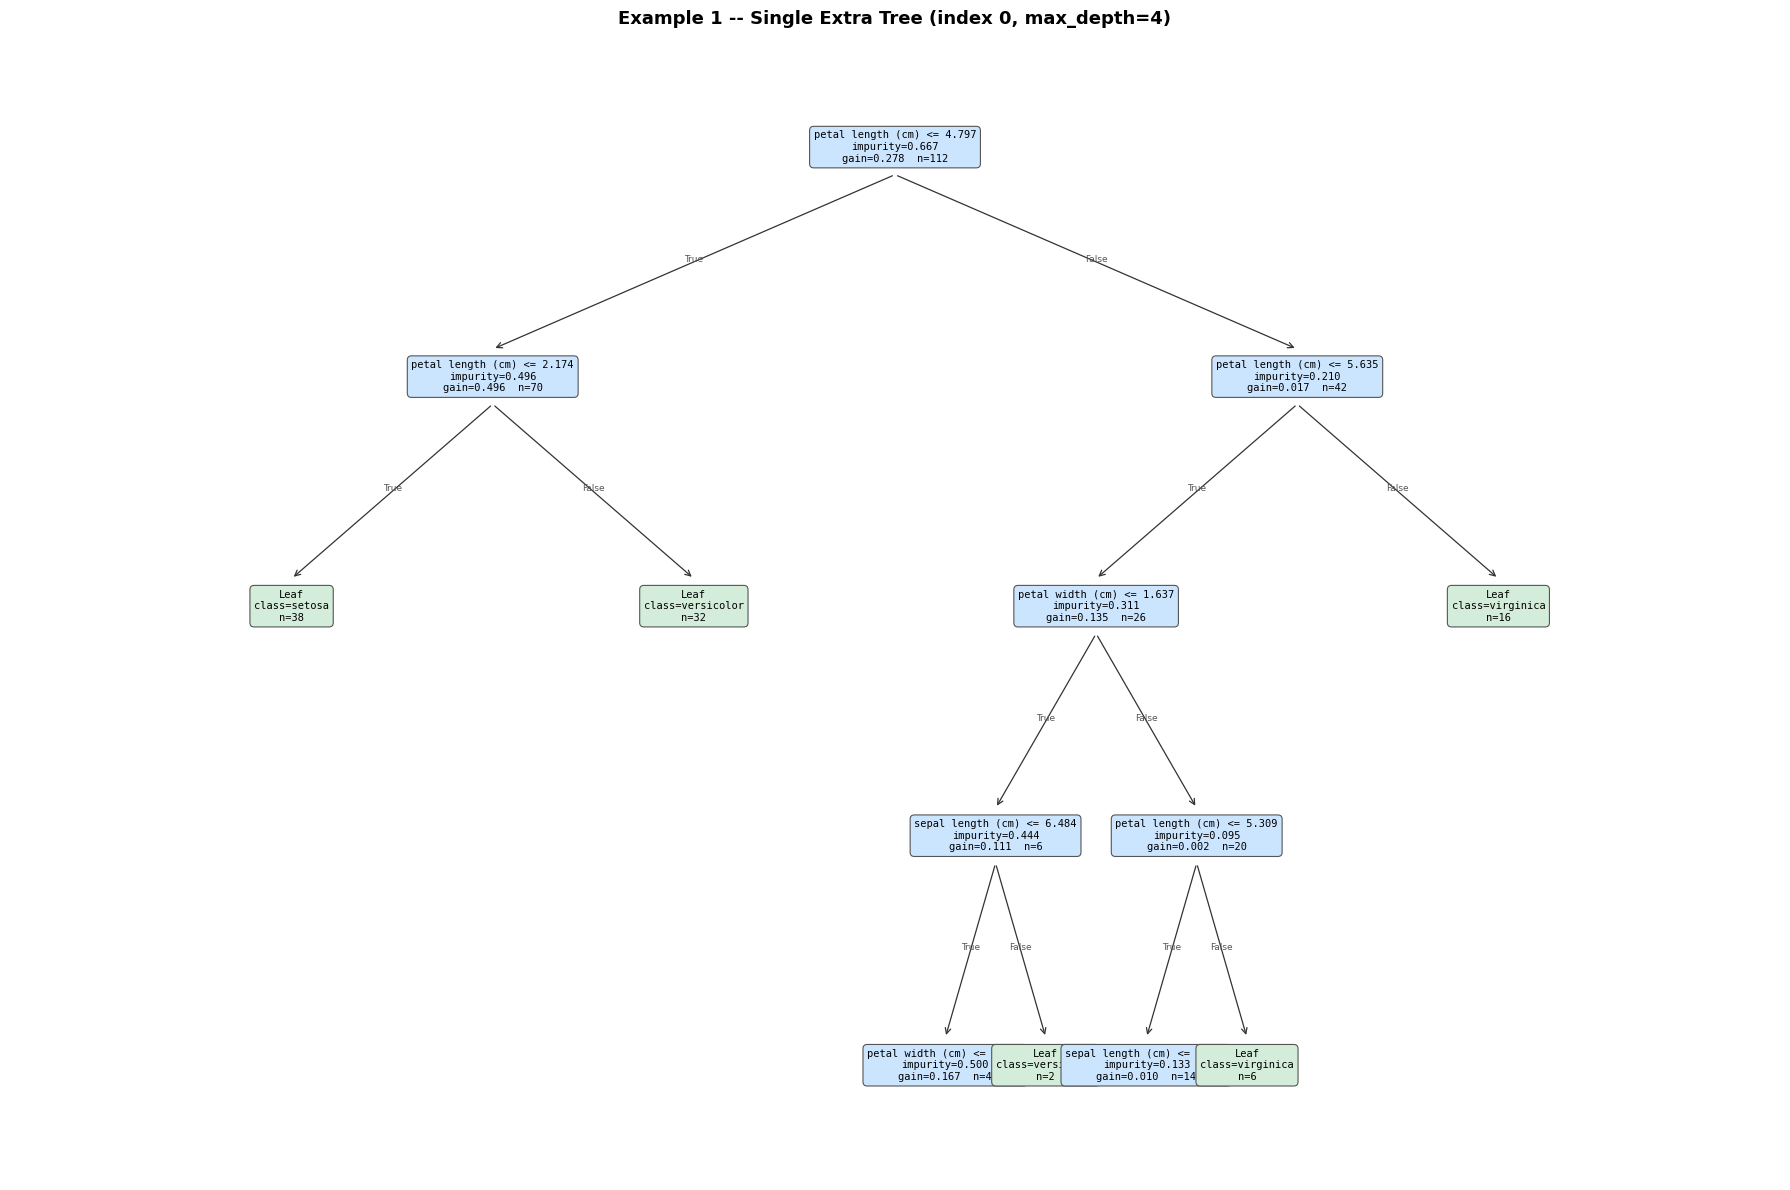

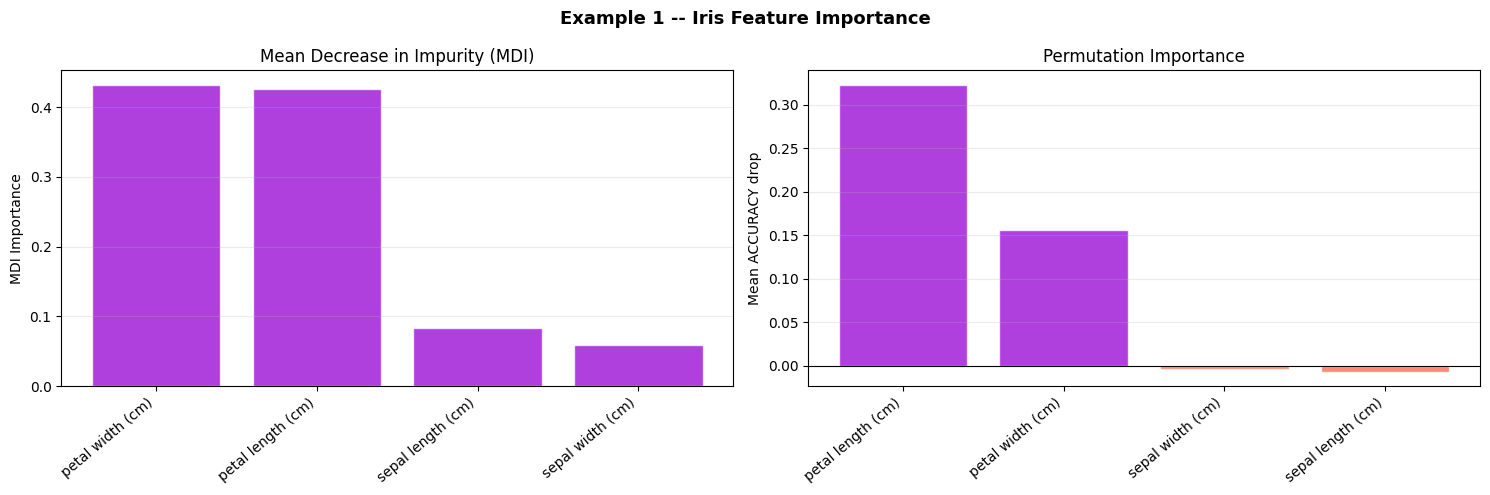


Test metrics:
  accuracy        = 0.921053
  precision       = 0.924603
  recall          = 0.923077
  f1              = 0.922963
  log_loss        = 0.128907


In [4]:
# Decision boundary (petal length vs petal width)
plot_decision_boundary(
    et1, X_tr1, y_tr1,
    feature_names=iris.feature_names,
    feat_x=2, feat_y=3,
    title='Example 1 -- Iris Decision Boundary (petal dims)',
)

# Tree structure of tree #0
plot_tree(
    et1, tree_idx=0,
    feature_names=iris.feature_names,
    class_names=iris.target_names.tolist(),
    max_depth=4,
    title='Example 1 -- Single Extra Tree (index 0, max_depth=4)',
)

# Feature importances
plot_feature_importance(
    et1, X_te1, y_te1,
    feature_names=iris.feature_names,
    metric='accuracy', n_repeats=15,
    title='Example 1 -- Iris Feature Importance',
)

m1 = evaluate_metrics(et1, X_te1, y_te1)
print('\nTest metrics:')
for k, v in m1.items():
    print(f'  {k:15s} = {v:.6f}')

In [5]:
export_to_json(et1, 'json_model/et_iris.json')
generate_ino(
    json_path='json_model/et_iris.json',
    output_dir='arduino_code/iris_ino',
    board='esp32',
    task='classification',
    sample_x=X_te1[0].astype(np.float32),
)

Model exported -> json_model/et_iris.json
Header  -> arduino_code/iris_ino\ETModel.h
Sketch  -> arduino_code/iris_ino\sketch.ino
Reference prediction: class 0


---
## Example 2 -- Breast Cancer: Binary Classification with Pruning

We train an Extra Trees ensemble on the 30-feature Breast Cancer dataset,
then apply cost-complexity pruning to reduce model size for deployment,
and compare classification metrics before and after pruning.

=== Example 2 -- Breast Cancer Binary Classification + Pruning ===
  Trees   40/200  |  F1 = 0.943990
  Trees   80/200  |  F1 = 0.943452
  Trees  120/200  |  F1 = 0.943452
  Trees  160/200  |  F1 = 0.943452
  Trees  200/200  |  F1 = 0.943452


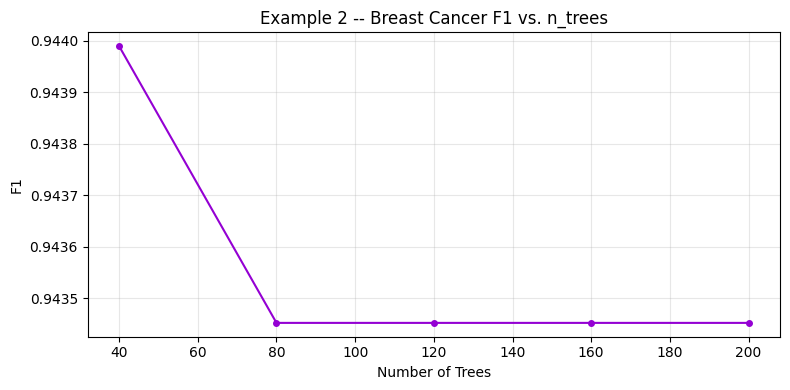


Before pruning: leaves=10709
  accuracy        = 0.947368
  precision       = 0.943452
  recall          = 0.943452
  f1              = 0.943452
  log_loss        = 0.111250


In [6]:
print('=== Example 2 -- Breast Cancer Binary Classification + Pruning ===')

from vi import cost_complexity_prune, min_impurity_prune

bc = load_breast_cancer()
scaler2 = StandardScaler()
X_sc2 = scaler2.fit_transform(bc.data).astype(np.float64)
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X_sc2, bc.target, test_size=0.2, random_state=7, stratify=bc.target,
)

et2 = ExtraTreesModel(
    n_estimators=200,
    task='classification',
    criterion='entropy',
    max_depth=None,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=7,
)
history2 = train_model(
    et2, X_tr2, y_tr2,
    X_val=X_te2, y_val=y_te2,
    metric='f1', log_every=40,
)
plot_training_history(history2, metric_name='F1',
                      title='Example 2 -- Breast Cancer F1 vs. n_trees')

m2_before = evaluate_metrics(et2, X_te2, y_te2)
n_leaves_before = sum(t.get_n_leaves() for t in et2.estimators_)
print(f'\nBefore pruning: leaves={n_leaves_before}')
for k, v in m2_before.items():
    print(f'  {k:15s} = {v:.6f}')


After pruning (alpha=0.005): leaves=1849
  accuracy        = 0.947368
  precision       = 0.953947
  recall          = 0.933532
  f1              = 0.942230
  log_loss        = 0.292288

Leaf reduction: 10709 -> 1849 (82.7% smaller)


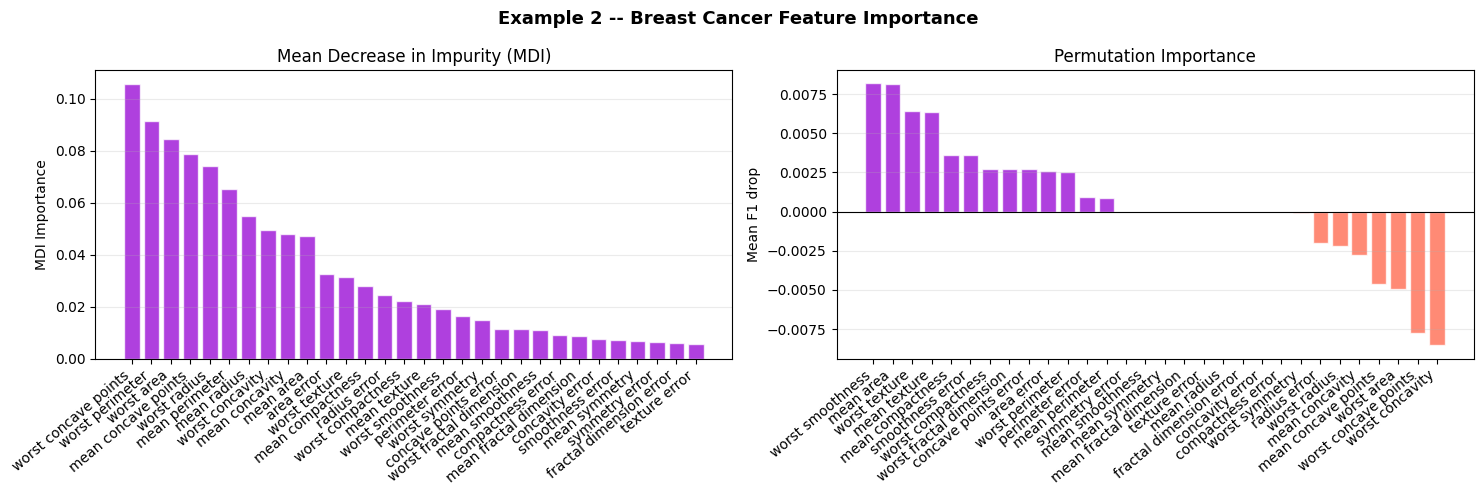

In [7]:
# Apply cost-complexity pruning (alpha=0.005)
import copy
et2_pruned = copy.deepcopy(et2)
for tree in et2_pruned.estimators_:
    cost_complexity_prune(tree, X_te2, y_te2, alpha=0.005)

m2_after = evaluate_metrics(et2_pruned, X_te2, y_te2)
n_leaves_after = sum(t.get_n_leaves() for t in et2_pruned.estimators_)
print(f'\nAfter pruning (alpha=0.005): leaves={n_leaves_after}')
for k, v in m2_after.items():
    print(f'  {k:15s} = {v:.6f}')
print(f'\nLeaf reduction: {n_leaves_before} -> {n_leaves_after} '
      f'({100*(1-n_leaves_after/n_leaves_before):.1f}% smaller)')

plot_feature_importance(
    et2, X_te2, y_te2,
    feature_names=bc.feature_names.tolist(),
    metric='f1', n_repeats=10,
    title='Example 2 -- Breast Cancer Feature Importance',
)

In [8]:
export_to_json(et2_pruned, 'json_model/et_bc_pruned.json')
generate_ino(
    json_path='json_model/et_bc_pruned.json',
    output_dir='arduino_code/bc_ino',
    board='avr',
    use_flash=True,
    task='classification',
    sample_x=X_te2[0].astype(np.float32),
)

Model exported -> json_model/et_bc_pruned.json
Header  -> arduino_code/bc_ino\ETModel.h
Sketch  -> arduino_code/bc_ino\sketch.ino
Reference prediction: class 0


---
## Example 3 -- Regression with Uncertainty and Partial Dependence

We train a regression Extra Trees ensemble on a synthetic heteroskedastic
dataset, visualise the ensemble prediction variance (epistemic uncertainty),
and plot partial dependence curves for each input feature.

=== Example 3 -- Regression with Uncertainty and Partial Dependence ===
  Trees   40/200  |  R2 = 0.779364
  Trees   80/200  |  R2 = 0.782027
  Trees  120/200  |  R2 = 0.794514
  Trees  160/200  |  R2 = 0.791140
  Trees  200/200  |  R2 = 0.790062


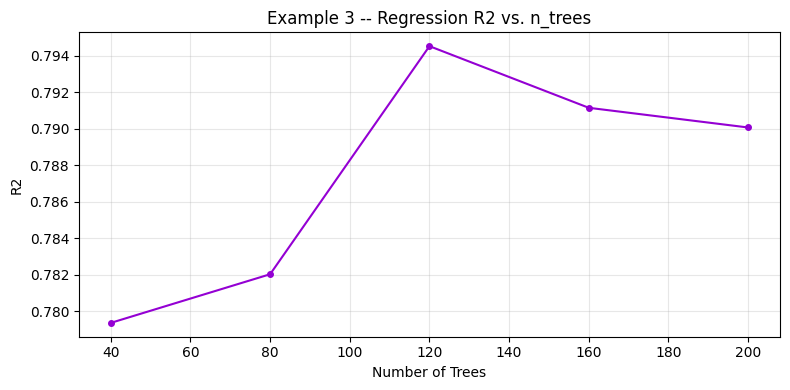

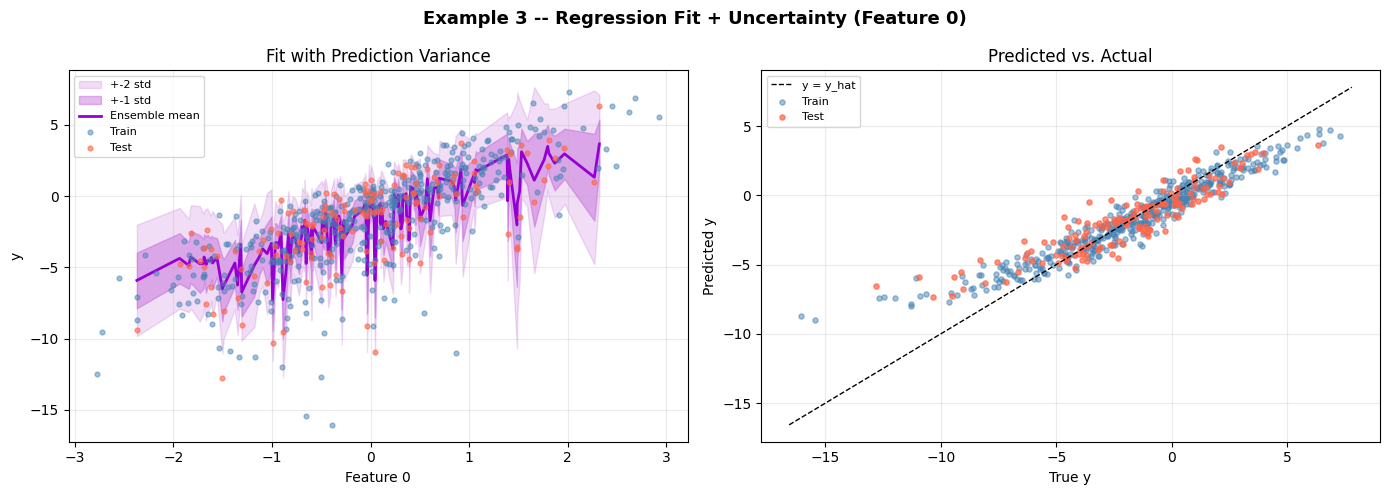

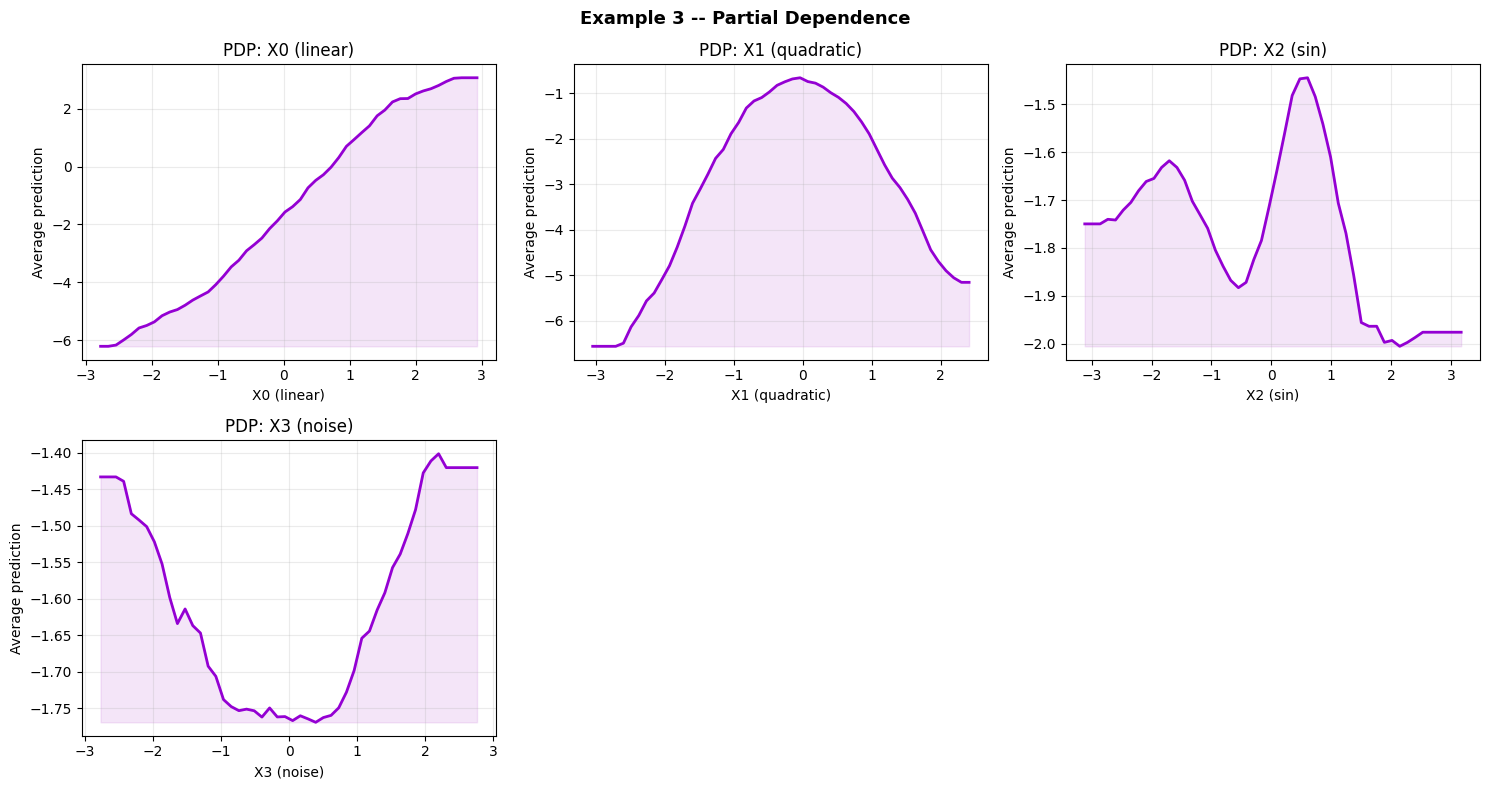


Test metrics:
  mse        = 2.218733
  mae        = 1.130655
  rmse       = 1.489541
  r2         = 0.790062
  mape       = 94.691311


In [9]:
print('=== Example 3 -- Regression with Uncertainty and Partial Dependence ===')

np.random.seed(0)
N    = 600
X3   = np.random.randn(N, 4).astype(np.float64)
y3   = (
    2.5 * X3[:, 0]
    - 1.8 * X3[:, 1] ** 2
    + np.sin(3.0 * X3[:, 2])
    + np.random.randn(N) * (0.5 + 0.5 * np.abs(X3[:, 0]))
).astype(np.float64)

X_tr3, X_te3, y_tr3, y_te3 = train_test_split(
    X3, y3, test_size=0.25, random_state=0,
)

et3 = ExtraTreesModel(
    n_estimators=200,
    task='regression',
    criterion='mse',
    max_depth=None,
    min_samples_leaf=3,
    max_features='sqrt',
    random_state=0,
)
history3 = train_model(
    et3, X_tr3, y_tr3,
    X_val=X_te3, y_val=y_te3,
    metric='r2', log_every=40,
)
plot_training_history(history3, metric_name='R2',
                      title='Example 3 -- Regression R2 vs. n_trees')

plot_regression_fit(
    et3, X_tr3, y_tr3, X_te3, y_te3,
    feature_idx=0,
    title='Example 3 -- Regression Fit + Uncertainty (Feature 0)',
)
plot_partial_dependence(
    et3, X3,
    feature_names=['X0 (linear)', 'X1 (quadratic)', 'X2 (sin)', 'X3 (noise)'],
    title='Example 3 -- Partial Dependence',
)
m3 = evaluate_metrics(et3, X_te3, y_te3, task='regression')
print('\nTest metrics:')
for k, v in m3.items():
    print(f'  {k:10s} = {v:.6f}')

In [10]:
export_to_json(et3, 'json_model/et_reg.json')
generate_ino(
    json_path='json_model/et_reg.json',
    output_dir='arduino_code/reg_ino',
    board='esp32',
    task='regression',
    sample_x=X_te3[0].astype(np.float32),
)

Model exported -> json_model/et_reg.json
Header  -> arduino_code/reg_ino\ETModel.h
Sketch  -> arduino_code/reg_ino\sketch.ino
Reference prediction: 0.126789


---
## Example 4 -- Wine: Criterion and max_features Comparison

We compare all four splitting criteria and three max_features settings
on the Wine dataset, plot the epistemic uncertainty map in the 2-D
PCA projection of the feature space, and export the best model for AVR.

=== Example 4 -- Wine: Criterion and max_features Comparison ===
  gini+sqrt             acc=1.0000
  gini+log2             acc=1.0000
  gini+None             acc=1.0000
  entropy+sqrt          acc=1.0000
  entropy+log2          acc=1.0000
  entropy+None          acc=0.9778


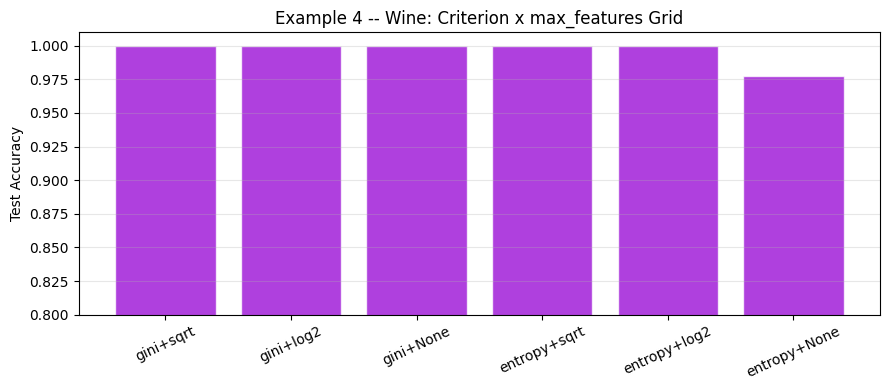

In [11]:
print('=== Example 4 -- Wine: Criterion and max_features Comparison ===')

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

wine  = load_wine()
X_w   = StandardScaler().fit_transform(wine.data).astype(np.float64)
y_w   = wine.target
X_trw, X_tew, y_trw, y_tew = train_test_split(
    X_w, y_w, test_size=0.25, random_state=99, stratify=y_w,
)

# Criterion comparison
results = {}
for crit in CRITERION_NAMES[:2]:   # gini, entropy for classification
    for mf in ['sqrt', 'log2', None]:
        key = f'{crit}+{mf}'
        m   = ExtraTreesModel(
            n_estimators=100, task='classification',
            criterion=crit, max_features=mf, random_state=99,
        )
        m.fit(X_trw, y_trw)
        acc = compute_loss('accuracy', y_tew, m.predict(X_tew))
        results[key] = acc
        print(f'  {key:20s}  acc={acc:.4f}')

# Bar chart comparison
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(list(results.keys()), list(results.values()),
       color='darkviolet', alpha=0.75, edgecolor='white')
ax.set_ylabel('Test Accuracy')
ax.set_title('Example 4 -- Wine: Criterion x max_features Grid')
ax.tick_params(axis='x', rotation=25)
ax.set_ylim(0.8, 1.01)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

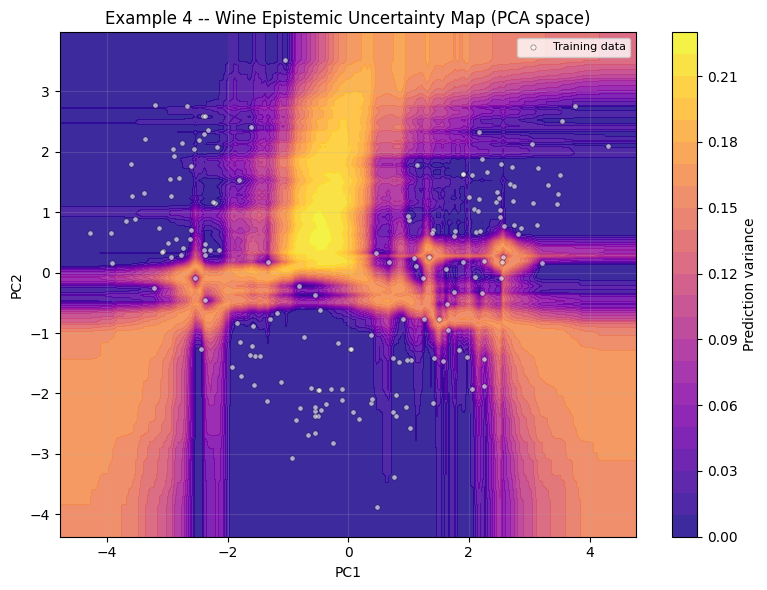

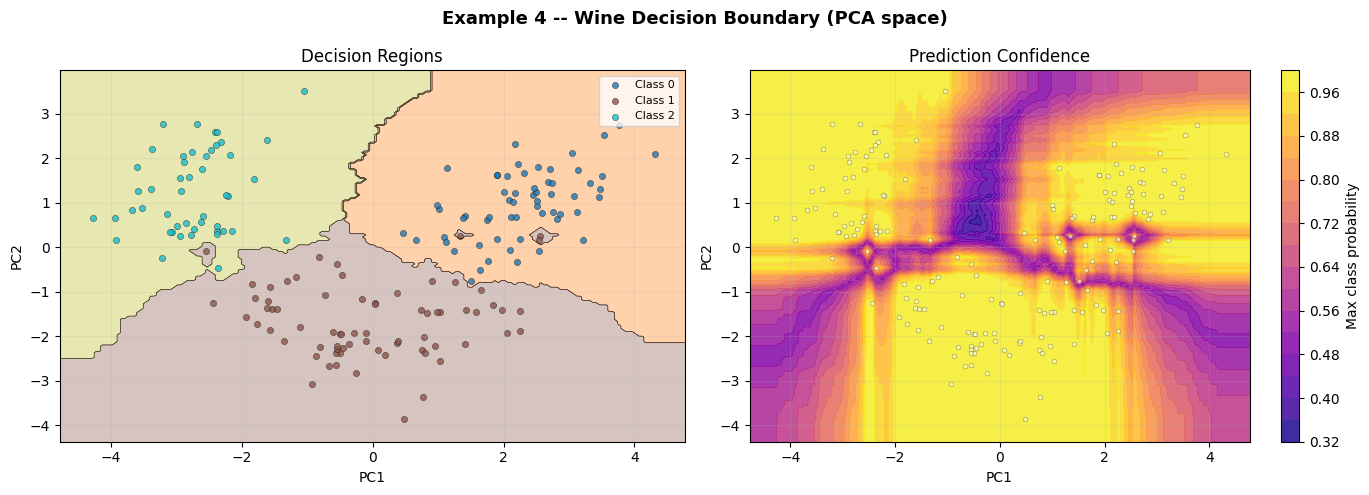

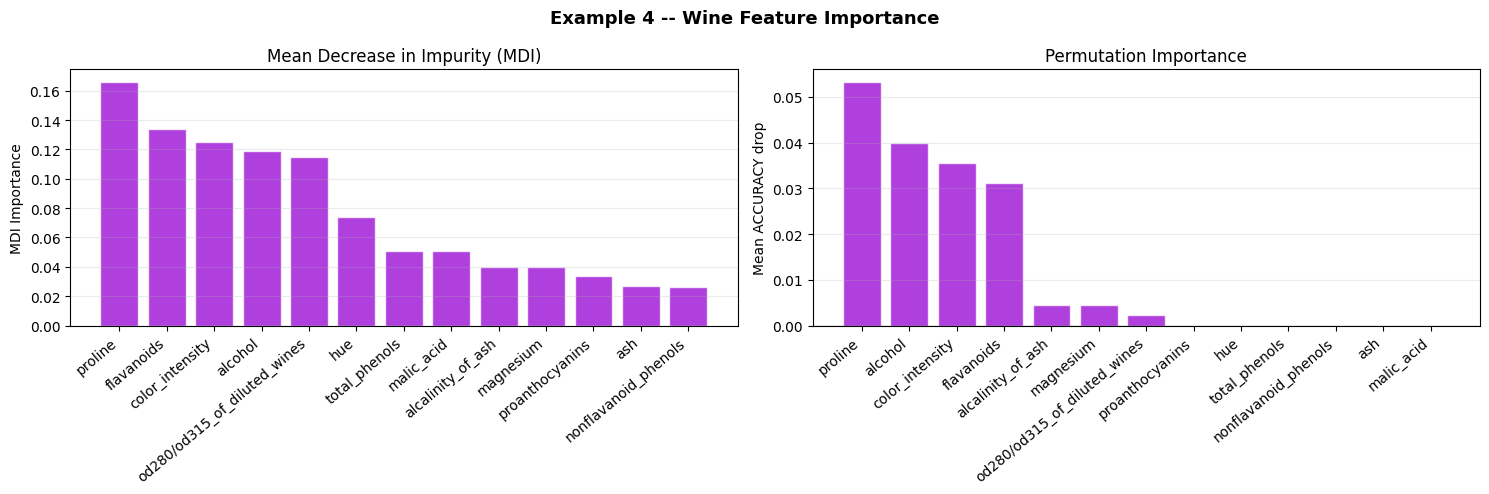


Test metrics:
  accuracy        = 1.000000
  precision       = 1.000000
  recall          = 1.000000
  f1              = 1.000000
  log_loss        = 0.130422


In [12]:
# Best model: gini + sqrt
et4 = ExtraTreesModel(
    n_estimators=200, task='classification',
    criterion='gini', max_features='sqrt',
    max_depth=None, min_samples_leaf=1, random_state=99,
)
et4.fit(X_trw, y_trw)

# 2-D PCA for uncertainty map
pca  = PCA(n_components=2, random_state=99)
X_2d = pca.fit_transform(X_w)
et4_2d = ExtraTreesModel(
    n_estimators=200, task='classification',
    criterion='gini', max_features='sqrt', random_state=99,
)
et4_2d.fit(X_2d, y_w)

plot_prediction_variance(
    et4_2d, X_2d, y_w,
    feat_x=0, feat_y=1,
    feature_names=['PC1', 'PC2'],
    title='Example 4 -- Wine Epistemic Uncertainty Map (PCA space)',
)
plot_decision_boundary(
    et4_2d, X_2d, y_w,
    feature_names=['PC1', 'PC2'],
    feat_x=0, feat_y=1,
    title='Example 4 -- Wine Decision Boundary (PCA space)',
)
plot_feature_importance(
    et4, X_tew, y_tew,
    feature_names=wine.feature_names,
    metric='accuracy', n_repeats=10,
    title='Example 4 -- Wine Feature Importance',
)
m4 = evaluate_metrics(et4, X_tew, y_tew)
print('\nTest metrics:')
for k, v in m4.items():
    print(f'  {k:15s} = {v:.6f}')

In [13]:
export_to_json(et4, 'json_model/et_wine.json')
generate_ino(
    json_path='json_model/et_wine.json',
    output_dir='arduino_code/wine_ino',
    board='avr',
    use_flash=True,
    task='classification',
    sample_x=X_tew[0].astype(np.float32),
)

Model exported -> json_model/et_wine.json
Header  -> arduino_code/wine_ino\ETModel.h
Sketch  -> arduino_code/wine_ino\sketch.ino
Reference prediction: class 2
